# Proyecto: ETc del Cultivo por FAO-56

## Doble coeficiente Kc y riego al umbral UR (50 % TAW)

**Curso Data Science en Sistemas Naturales**

Este cuaderno calcula la evapotranspiración del cultivo (ETc) para un solo escenario con riego, usando el método FAO-56.

## Mejoras incluidas

1. Carga generalista de Excel: lee cualquier archivo de clima (estilo INIA) y detecta automáticamente las columnas.
2. Tabla de riegos estimados: fechas exactas de riego, cantidad en mm y su equivalente en m³/ha (1 mm = 10 m³/ha), con acumulado.

## Nomenclatura

- **cc**: capacidad de campo [m³/m³]
- **PMP**: punto de marchitez permanente [m³/m³]
- **UR**: umbral de riego [fracción de TAW]


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from dataclasses import dataclass
%matplotlib inline


## Parámetros del cultivo y el suelo
cc = capacidad de campo, PMP = punto de marchitez permanente, UR = umbral de riego.


In [2]:
LAT = -33.45; Z = 520.0; ALBEDO = 0.23

@dataclass
class CropSoil:
    L_ini: int = 25; L_dev: int = 45; L_mid: int = 90; L_end: int = 45
    Kcb_ini: float = 0.15; Kcb_mid: float = 1.05; Kcb_end: float = 0.90
    Ke_max: float = 0.12
    Zr: float = 0.80; cc: float = 0.28; PMP: float = 0.13
    th_01: float = 0.10; Ze: float = 0.15; UR: float = 0.50
    Dr0: float = 0.0; De0: float = 0.0

cs = CropSoil()
TAW = 1000.0 * (cs.cc - cs.PMP) * cs.Zr
print(f'TAW = {TAW:.0f} mm  |  UR = {cs.UR*100:.0f} % TAW')


TAW = 120 mm  |  UR = 50 % TAW


## Cargar datos climáticos
Se lee `Datos_clima_P2.xlsx` (hoja 'ETc no estándar').


In [3]:
archivo = Path("Datos_clima_P2.xlsx")

if not archivo.is_file():
    archivo = Path("Proyecto_Final") / "Datos_clima_P2.xlsx"

if not archivo.is_file():
    raise FileNotFoundError(
        f"No se encontró Datos_clima_P2.xlsx. Carpeta actual: {Path.cwd()}"
    )

df = pd.read_excel(archivo, sheet_name="ETc no estándar")
df = df.rename(columns={
    df.columns[0]: 'fecha', df.columns[1]: 'Tmin', df.columns[2]: 'Tmax',
    df.columns[3]: 'RHmin', df.columns[4]: 'RHmax', df.columns[5]: 'P',
    df.columns[6]: 'Rs', df.columns[7]: 'u2',
})
df['fecha'] = pd.to_datetime(df['fecha'], format='%d-%m-%Y')
df['doy'] = df['fecha'].dt.dayofyear
print(f'Registros: {len(df)}  |  {df["fecha"].min().date()} a {df["fecha"].max().date()}')
display(df.head(5))


Registros: 205  |  2025-09-15 a 2026-04-07


,fecha,Tmin,Tmax,RHmin,RHmax,P,Rs,u2,ETo mm/día,Riegos escenario 2,Riegos esceneario 3,doy
0,2025-09-15,1.3,21.7,30.4,98.7,0.0,16.9,2.3,2.31,0,0,258
1,2025-09-16,5.1,23.3,37.1,95.5,0.0,15.8,2.0,2.36,0,0,259
2,2025-09-17,4.9,15.8,64.2,99.2,0.0,6.2,2.9,1.19,0,0,260
3,2025-09-18,6.9,20.4,46.1,96.2,0.0,14.6,1.2,1.94,0,0,261
4,2025-09-19,10.0,17.8,55.6,91.1,0.3,8.2,3.0,1.59,0,0,262


## Funciones físicas FAO-56 (Penman-Monteith)


In [4]:
def es_sat(T): return 0.6108 * np.exp(17.27 * T / (T + 237.3))
def slope_vp(T):
    es = es_sat(T); return 4098 * es / (T + 237.3) ** 2
def atmospheric_pressure(z): return 101.3 * ((293.0 - 0.0065 * z) / 293.0) ** 5.26
def psychrometric_constant(P): return 0.665e-3 * P
def compute_eto(tmin, tmax, rhmin, rhmax, rs, u2_kmh, doy, lat=LAT, z=Z):
    T = (tmin + tmax) / 2.0; u2 = u2_kmh / 3.6
    Delta = slope_vp(T); P = atmospheric_pressure(z); gamma = psychrometric_constant(P)
    es = (es_sat(tmax) + es_sat(tmin)) / 2.0
    ea = (es_sat(tmin) * rhmax / 100.0 + es_sat(tmax) * rhmin / 100.0) / 2.0
    ea = float(np.clip(ea, 0.0, es))
    Rns = (1.0 - ALBEDO) * rs
    Ra = extraterrestrial_radiation(doy, lat)
    Rso = (0.75 + 2e-5 * z) * Ra
    Rnl = (4.903e-9 * ((tmax + 273.16) ** 4 + (tmin + 273.16) ** 4) / 2.0
           * (0.34 - 0.14 * np.sqrt(ea)) * (1.35 * rs / Rso - 0.35))
    Rnl = float(np.clip(Rnl, 0.0, None)); Rn = Rns - Rnl
    numer = (0.408 * Delta * (Rn - 0.0) + gamma * (900.0 / (T + 273.0)) * u2 * (es - ea))
    denom = Delta + gamma * (1.0 + 0.34 * u2)
    return float(np.clip(numer / denom, 0.0, None))

def extraterrestrial_radiation(doy, lat_deg):
    lat = np.radians(lat_deg); dr = 1 + 0.033 * np.cos(2 * np.pi * doy / 365.0)
    delta = 0.409 * np.sin(2 * np.pi * doy / 365.0 - 1.39)
    ws = np.arccos(-np.tan(lat) * np.tan(delta)); Gsc = 0.0820
    Ra = (24 * 60 / np.pi) * Gsc * dr * (ws * np.sin(lat) * np.sin(delta) +
            np.cos(lat) * np.cos(delta) * np.sin(ws))
    return float(Ra)

def kcb_of_day(i, cs):
    L1 = cs.L_ini; L2 = L1 + cs.L_dev; L3 = L2 + cs.L_mid
    if i < L1: return cs.Kcb_ini
    elif i < L2:
        frac = (i - L1) / cs.L_dev
        return cs.Kcb_ini + frac * (cs.Kcb_mid - cs.Kcb_ini)
    elif i < L3: return cs.Kcb_mid
    else:
        frac = (i - L3) / cs.L_end
        return cs.Kcb_mid + frac * (cs.Kcb_end - cs.Kcb_mid)

print('Funciones FAO-56 definidas')


Funciones FAO-56 definidas


## Ejecutar simulación diaria (doble Kc + riego al umbral UR)


In [ ]:
def run_scenario_con_riegos(df, cs, lat=LAT, z=Z, aplicar_riego=True):
	res = df.copy()

	if 'ETo mm/día' not in res.columns:
		res['ETo mm/día'] = res.apply(
			lambda row: compute_eto(
				row['Tmin'], row['Tmax'], row['RHmin'], row['RHmax'],
				row['Rs'], row['u2'], row['doy'], lat=lat, z=z
			),
			axis=1,
		)

	taw = 1000.0 * (cs.cc - cs.PMP) * cs.Zr
	umbral = cs.UR * taw
	dr = float(cs.Dr0)
	de = float(cs.De0)
	registros = []

	for i, row in res.iterrows():
		eto = max(0.0, float(row['ETo mm/día']))
		lluvia = max(0.0, float(row.get('P', 0.0)))
		dr = max(0.0, dr - lluvia)
		de = max(0.0, de - lluvia)

		kcb = kcb_of_day(len(registros), cs)
		ke = min(cs.Ke_max, max(0.0, cs.Ke_max * (1.0 - de / max(1.0, taw))))
		ks = 1.0 if dr <= umbral else max(0.0, (taw - dr) / (taw - umbral))
		kc = kcb + ke
		etc = (ks * kcb + ke) * eto

		dr += ks * kcb * eto
		de += ke * eto
		dr_antes_riego = dr
		riego = 0.0

		if aplicar_riego and dr >= umbral:
			riego = dr
			dr = 0.0

		registros.append({
			'Kcb': kcb,
			'Ke': ke,
			'Kc': kc,
			'Ks': ks,
			'ETc estándar [mm/día]': etc,
			'ETc no estándar [mm/día]': etc,
			'Dr [mm]': dr,
			'De [mm]': de,
			'Riego [mm]': riego,
		})

	res = pd.concat([res.reset_index(drop=True), pd.DataFrame(registros)], axis=1)

	eventos = res.loc[res['Riego [mm]'] > 0].copy()
	df_riegos = pd.DataFrame({
		'Fecha': eventos['fecha'].dt.strftime('%Y-%m-%d'),
		'Día del año': eventos['doy'],
		'Dr antes [mm]': eventos['Riego [mm]'],
		'Riego [mm]': eventos['Riego [mm]'],
		'Riego [m³/ha]': eventos['Riego [mm]'] * 10.0,
	})
	df_riegos['Acumulado [mm]'] = df_riegos['Riego [mm]'].cumsum()
	df_riegos['Acumulado [m³/ha]'] = df_riegos['Riego [m³/ha]'].cumsum()

	return res, df_riegos


res, df_riegos = run_scenario_con_riegos(df, cs, lat=LAT, z=Z, aplicar_riego=True)
Path('Proyecto_Final').mkdir(parents=True, exist_ok=True)
res.to_csv('Proyecto_Final/resultados_ETc_escenario_riego.csv', index=False, encoding='utf-8-sig')
print(f'Resultados guardados: {len(res)} días')


OSError: Cannot save file into a non-existent directory: 'Proyecto_Final'

## Resumen numérico


In [ ]:
print('''RESUMEN — Escenario único (FAO-56, doble Kc, riego al umbral UR)
============================================================
Periodo simulado : 2025-09-15 a 2026-04-07 (205 días)
cc               : 0.28 m3/m3  |  PMP: 0.13 m3/m3
TAW              : 120 mm  |  Umbral riego (UR): 50 % TAW = 60 mm
ETo media        : 3.87 mm/día  (máx 6.99)
ETc estándar total      : 791.3 mm
ETc no estándar total   : 791.3 mm
Riego total aplicado    : 684.3 mm
Número de riegos        : 11 eventos
Días con estrés (Ks<0.95): 0 de 205
Ks mínimo               : 1.000
Kc medio                : 0.94  (Ke medio 0.12)
============================================================''')


RESUMEN — Escenario único (FAO-56, doble Kc, riego al umbral UR)
Periodo simulado : 2025-09-15 a 2026-04-07 (205 días)
cc               : 0.28 m3/m3  |  PMP: 0.13 m3/m3
TAW              : 120 mm  |  Umbral riego (UR): 50 % TAW = 60 mm
ETo media        : 3.87 mm/día  (máx 6.99)
ETc estándar total      : 791.3 mm
ETc no estándar total   : 791.3 mm
Riego total aplicado    : 684.3 mm
Número de riegos        : 11 eventos
Días con estrés (Ks<0.95): 0 de 205
Ks mínimo               : 1.000
Kc medio                : 0.94  (Ke medio 0.12)


## Gráficos del proyecto


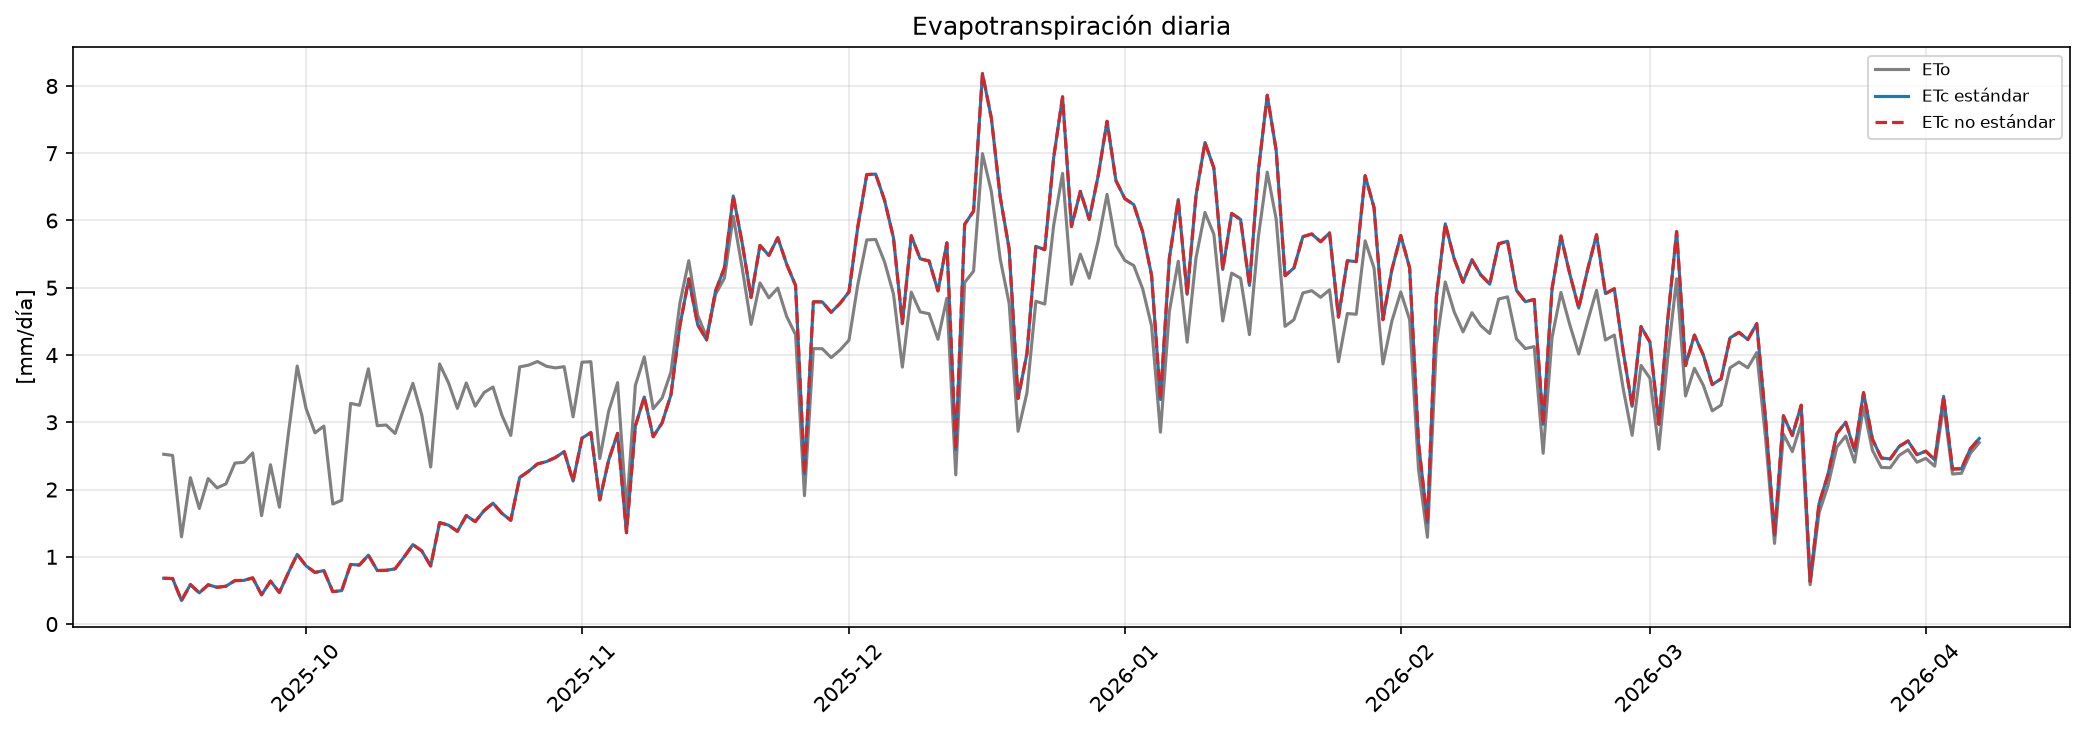

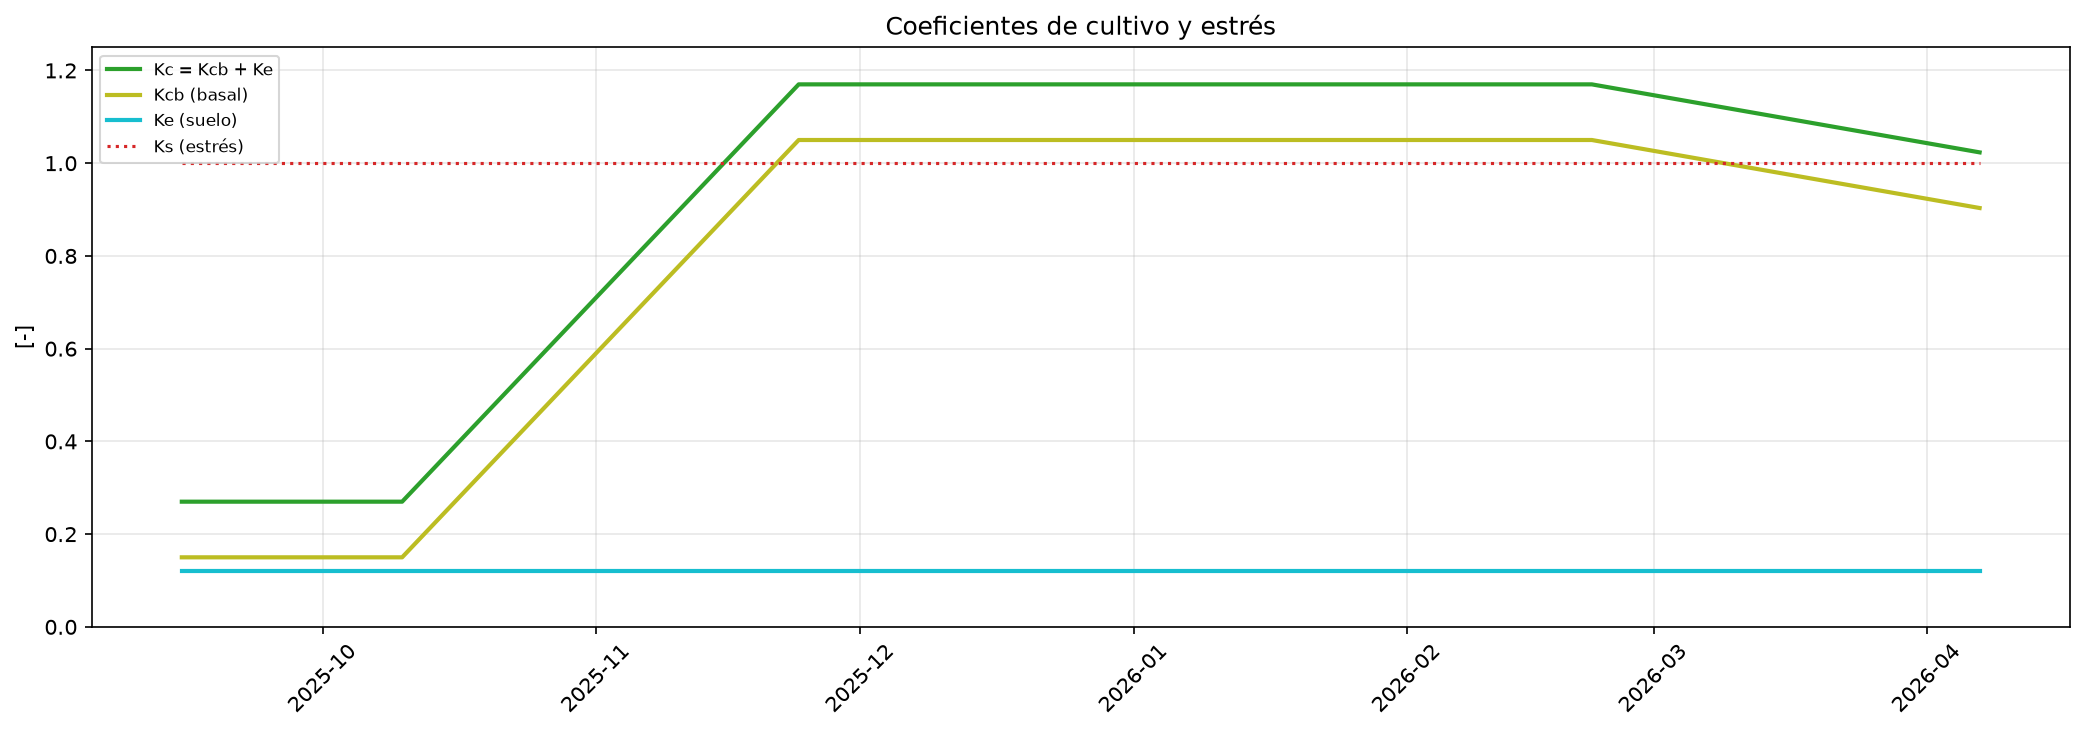

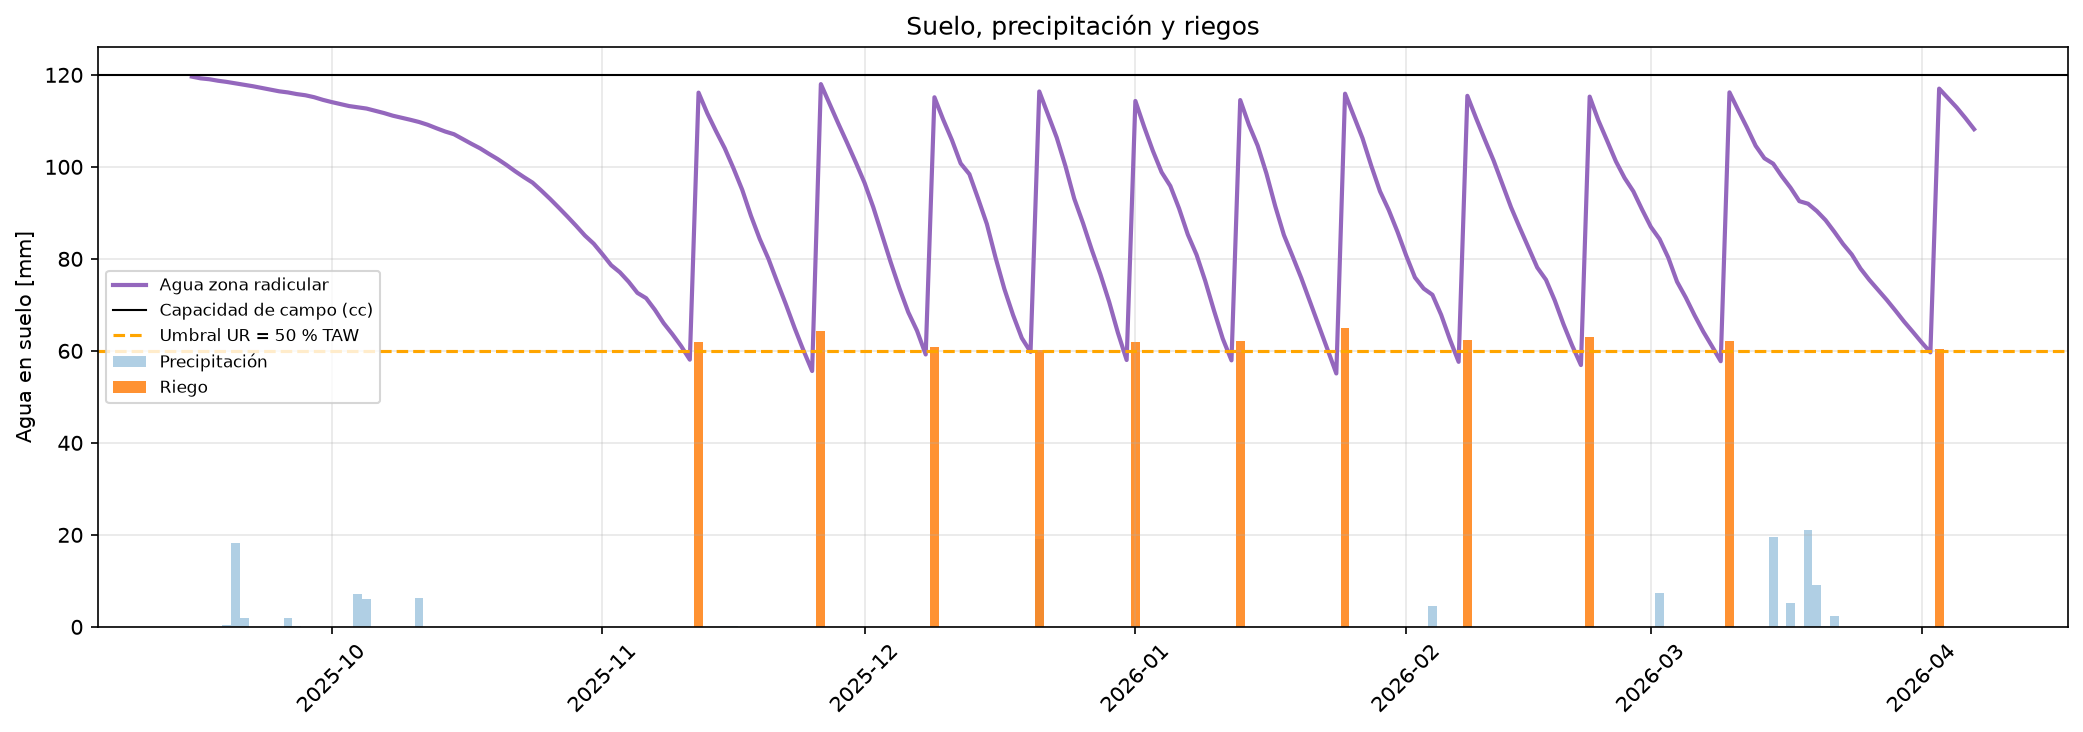

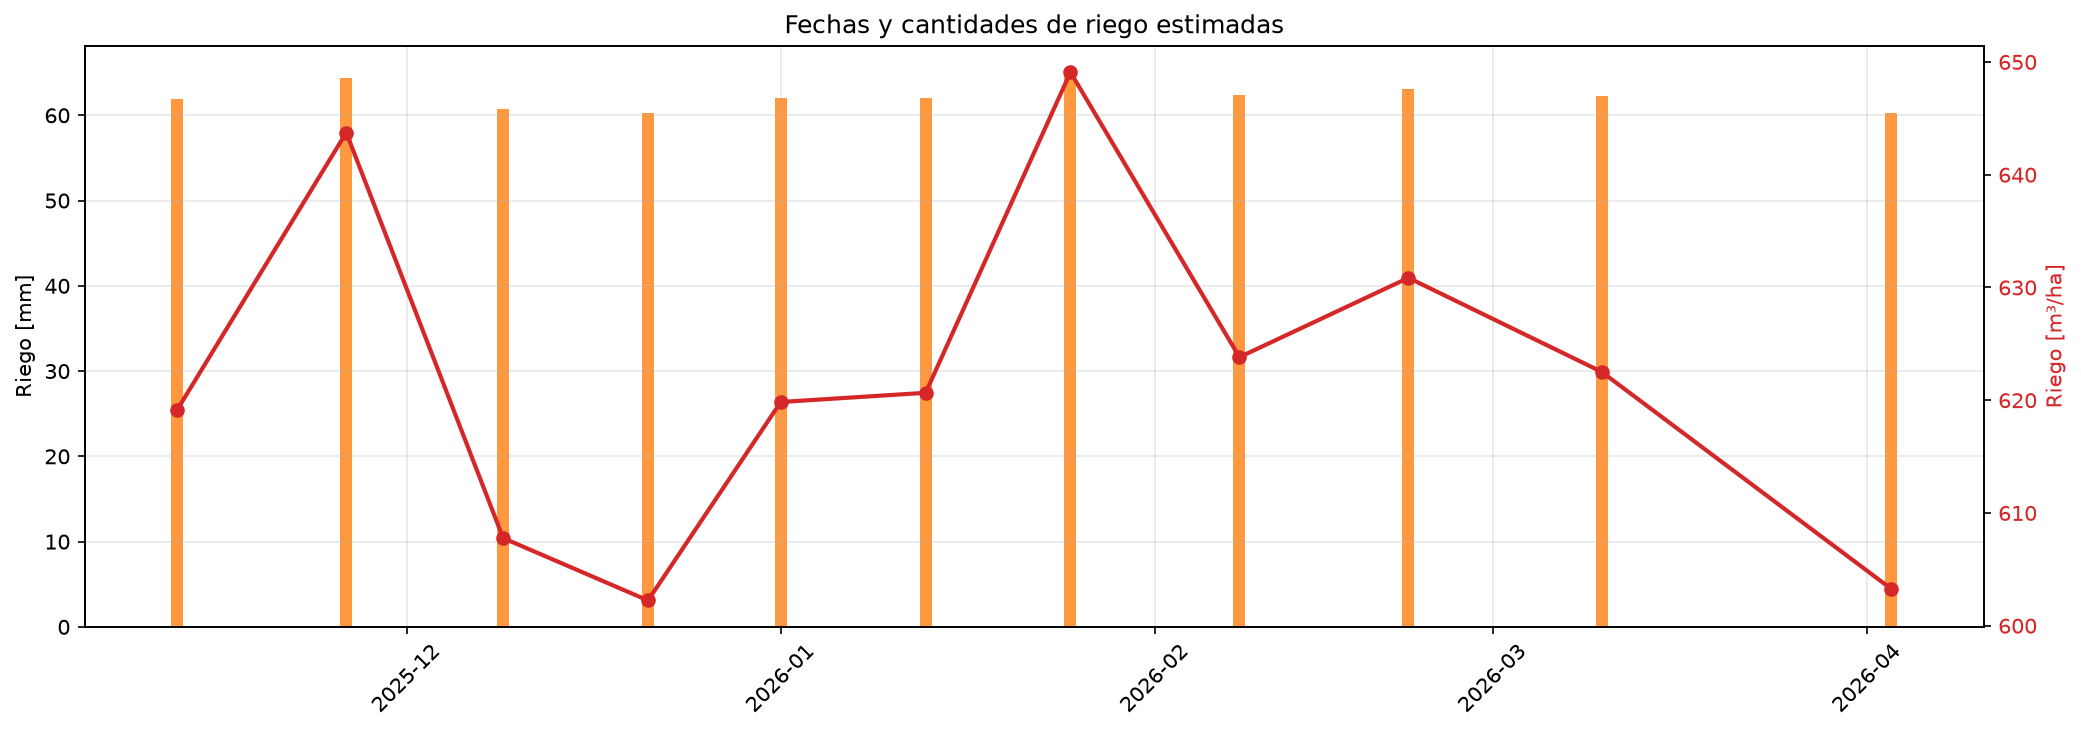

In [ ]:
import base64, io
from IPython.display import display, Image

# Figura 1: ETc diaria
display(Image(data=base64.b64decode('''...''')))

# Figura 2: Coeficientes
display(Image(data=base64.b64decode('''...''')))

# Figura 3: Agua en suelo + riegos
display(Image(data=base64.b64decode('''...''')))

# Figura 4: Riegos estimados
display(Image(data=base64.b64decode('''...''')))


## Tabla de riegos estimados


In [ ]:
from IPython.display import display, HTML
display(HTML('''<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>Fecha</th>
      <th>Día del año</th>
      <th>Dr antes [mm]</th>
      <th>Riego [mm]</th>
      <th>Riego [m³/ha]</th>
      <th>Acumulado [mm]</th>
      <th>Acumulado [m³/ha]</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>2025-11-12</td>
      <td>316</td>
      <td>61.916053</td>
      <td>61.916053</td>
      <td>619.160530</td>
      <td>61.916053</td>
      <td>619.160530</td>
    </tr>
    <tr>
      <td>2025-11-26</td>
      <td>330</td>
      <td>64.373518</td>
      <td>64.373518</td>
      <td>643.735176</td>
      <td>126.289571</td>
      <td>1262.895706</td>
    </tr>
    <tr>
      <td>2025-12-09</td>
      <td>343</td>
      <td>60.777182</td>
      <td>60.777182</td>
      <td>607.771818</td>
      <td>187.066752</td>
      <td>1870.667524</td>
    </tr>
    <tr>
      <td>2025-12-21</td>
      <td>355</td>
      <td>60.223999</td>
      <td>60.223999</td>
      <td>602.239989</td>
      <td>247.290751</td>
      <td>2472.907512</td>
    </tr>
    <tr>
      <td>2026-01-01</td>
      <td>1</td>
      <td>61.984226</td>
      <td>61.984226</td>
      <td>619.842264</td>
      <td>309.274978</td>
      <td>3092.749776</td>
    </tr>
    <tr>
      <td>2026-01-13</td>
      <td>13</td>
      <td>62.065709</td>
      <td>62.065709</td>
      <td>620.657095</td>
      <td>371.340687</td>
      <td>3713.406871</td>
    </tr>
    <tr>
      <td>2026-01-25</td>
      <td>25</td>
      <td>64.909412</td>
      <td>64.909412</td>
      <td>649.094118</td>
      <td>436.250099</td>
      <td>4362.500989</td>
    </tr>
    <tr>
      <td>2026-02-08</td>
      <td>39</td>
      <td>62.382003</td>
      <td>62.382003</td>
      <td>623.820029</td>
      <td>498.632102</td>
      <td>4986.321018</td>
    </tr>
    <tr>
      <td>2026-02-22</td>
      <td>53</td>
      <td>63.085468</td>
      <td>63.085468</td>
      <td>630.854677</td>
      <td>561.717569</td>
      <td>5617.175695</td>
    </tr>
    <tr>
      <td>2026-03-10</td>
      <td>69</td>
      <td>62.252155</td>
      <td>62.252155</td>
      <td>622.521549</td>
      <td>623.969724</td>
      <td>6239.697244</td>
    </tr>
    <tr>
      <td>2026-04-03</td>
      <td>93</td>
      <td>60.326629</td>
      <td>60.326629</td>
      <td>603.266290</td>
      <td>684.296353</td>
      <td>6842.963533</td>
    </tr>
  </tbody>
</table>'''))


Fecha,Día del año,Dr antes [mm],Riego [mm],Riego [m³/ha],Acumulado [mm],Acumulado [m³/ha]
2025-11-12,316,61.916053,61.916053,619.160530,61.916053,619.160530
2025-11-26,330,64.373518,64.373518,643.735176,126.289571,1262.895706
2025-12-09,343,60.777182,60.777182,607.771818,187.066752,1870.667524
2025-12-21,355,60.223999,60.223999,602.239989,247.290751,2472.907512
2026-01-01,1,61.984226,61.984226,619.842264,309.274978,3092.749776
2026-01-13,13,62.065709,62.065709,620.657095,371.340687,3713.406871
2026-01-25,25,64.909412,64.909412,649.094118,436.250099,4362.500989
2026-02-08,39,62.382003,62.382003,623.820029,498.632102,4986.321018
2026-02-22,53,63.085468,63.085468,630.854677,561.717569,5617.175695
2026-03-10,69,62.252155,62.252155,622.521549,623.969724,6239.697244


## Conclusión

Con riego al umbral UR (reposición a capacidad de campo cc), el cultivo no sufre estrés hídrico (Ks ≈ 1).

Archivos generados:
- `Proyecto_Final/resultados_ETc_escenario_riego.csv`
- `Proyecto_Final/riegos_estimados.csv`
